# 三方法比較 — HRIPCB PCB 瑕疵偵測
### `notebooks/04_methods_comparison.ipynb` · pcb-aoi · Stage 4

本 notebook 整合 Stage 1/2/3 三種方法,在**同一個 test split(seed=42、108 張
影像)**上比較,讓讀者在一份表 + 一組圖內看懂三方法的差異與取捨。**不重新訓練**。

## 1. 動機與設定

| Stage | 方法 | 一句話 |
|---|---|---|
| 1 | 傳統 CV(差影 + 形態學 + rule-based 分類) | 可解釋、零訓練,但分類撞牆 |
| 2 | R-CNN 風格(Stage 1 proposals + ResNet18) | CNN 解決分類,受 proposal recall 綁住 |
| 3 | YOLOv8n 端到端 | 單網路學定位 + 分類,突破瓶頸 |

**可比性保證**:三方法都在相同 test split(`build_splits(seed=42)` 的 test,
108 張影像)上評估。

> **註腳**:Stage 1 在**全資料集**上的 mAP@0.5 為 **27.4%**;與 Stage 2/3 比較時
> 一律使用同 test split(seed=42)的 **29.3%**,以保證可比性。

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd() / "04_methods_comparison.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"D:\ash-portfolio\pcb-aoi")
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
import pandas as pd
from src.hripcb import CLASSES, CLASS_ZH
FIG = ROOT / "results" / "figures"

## 2. 量化比較

> **註(precision 與 mAP@0.5 巧合相同)**:Stage 2 的 precision 與 mAP@0.5 在表中皆為 **0.8475**,但兩者為**獨立計算、數值巧合**,並非欄位誤填 —— precision 是各類 precision 的 macro 平均(精確值 **0.847512**)、mAP@0.5 是各類 AP 的平均(精確值 **0.847509**),到小數第 5 位才分歧。recall 欄(0.8834,macro recall)與 mAP 不同,無此情形。

In [2]:
df = pd.read_csv(ROOT / "results" / "comparison_table.csv")
df

,method,mAP@0.5,mAP@0.5:0.95,precision,recall,inference_ms,model_size_mb,notes
0,Stage 1:傳統 CV,0.2930,0.1410,0.2883,0.3908,641.3,NaN,差影+形態學;hand-crafted feature 分類撞牆
1,Stage 2:R-CNN 風格(proposals+CNN),0.8475,0.3899,0.8475,0.8834,13.6,44.8,ResNet18 forward(不含 Stage1 proposal 生成);受 prop...
2,Stage 3:YOLOv8n 端到端,0.9178,0.4672,0.9351,0.8616,5.4,6.3,"端到端,無 proposal 依賴;突破 short recall 瓶頸"


In [3]:
# per-class AP@0.5 三方法並排
data = json.loads((ROOT / "results" / "intermediate" / "comparison_data.json").read_text())
pc = data["per_class_ap50"]
rows = [{"class": c, "中文": CLASS_ZH[c],
         "S1": round(pc["stage1"][c]*100, 1), "S2": round(pc["stage2"][c]*100, 1),
         "S3": round(pc["stage3"][c]*100, 1)} for c in CLASSES]
pd.DataFrame(rows)

,class,中文,S1,S2,S3
0,missing_hole,缺孔,86.1,93.9,98.3
1,mouse_bite,鼠咬(缺口),2.6,94.8,88.9
2,open_circuit,斷路,5.9,94.1,86.1
3,short,短路,19.7,36.2,97.5
4,spur,毛刺(凸尖),0.4,91.2,92.6
5,spurious_copper,多餘銅(殘銅),61.0,98.3,87.3


### 2.1 PR 曲線、推論速度、逐樣本偵測對比

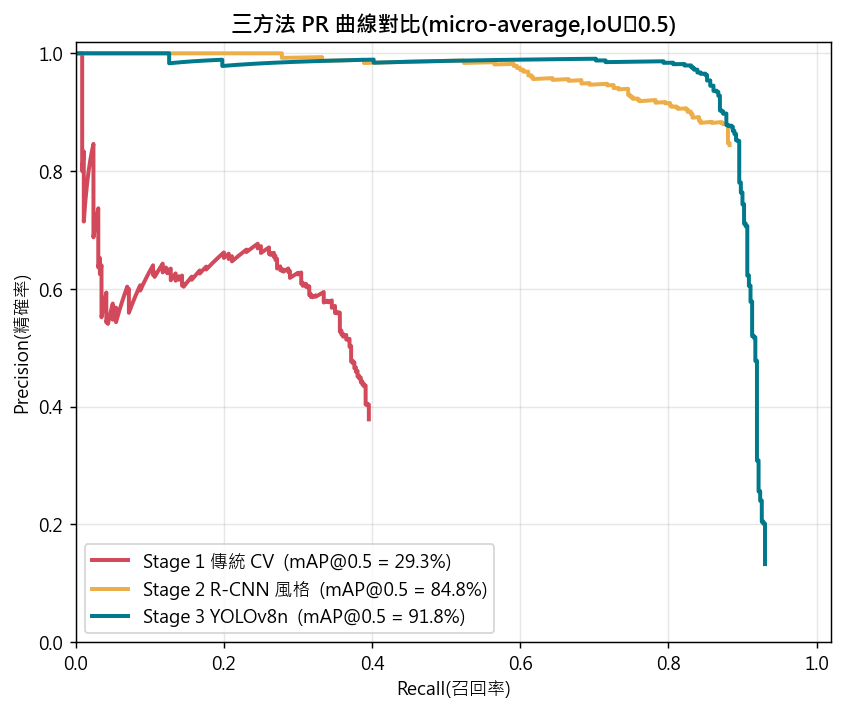

In [4]:
display(Image(filename=str(FIG / "04_pr_curves.png")))

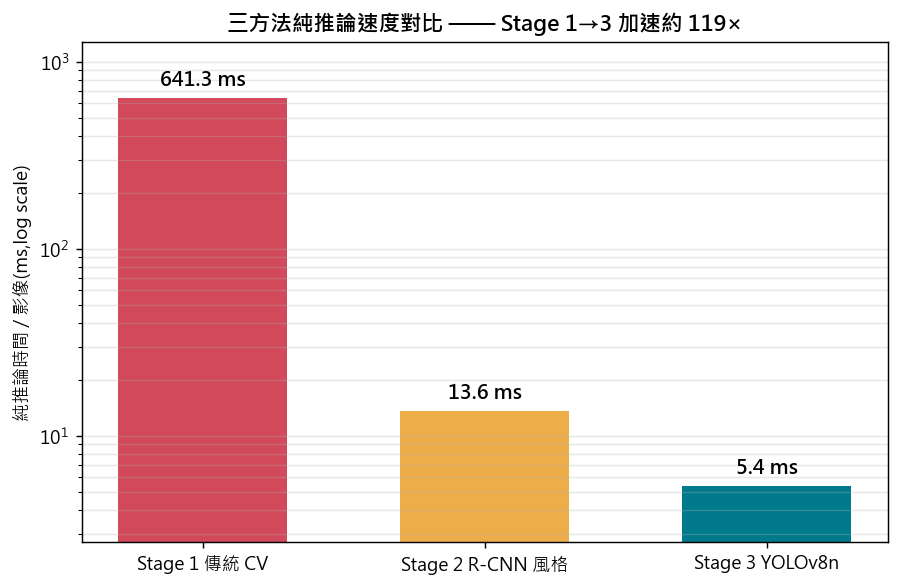

In [5]:
display(Image(filename=str(FIG / "04_speed_comparison.png")))

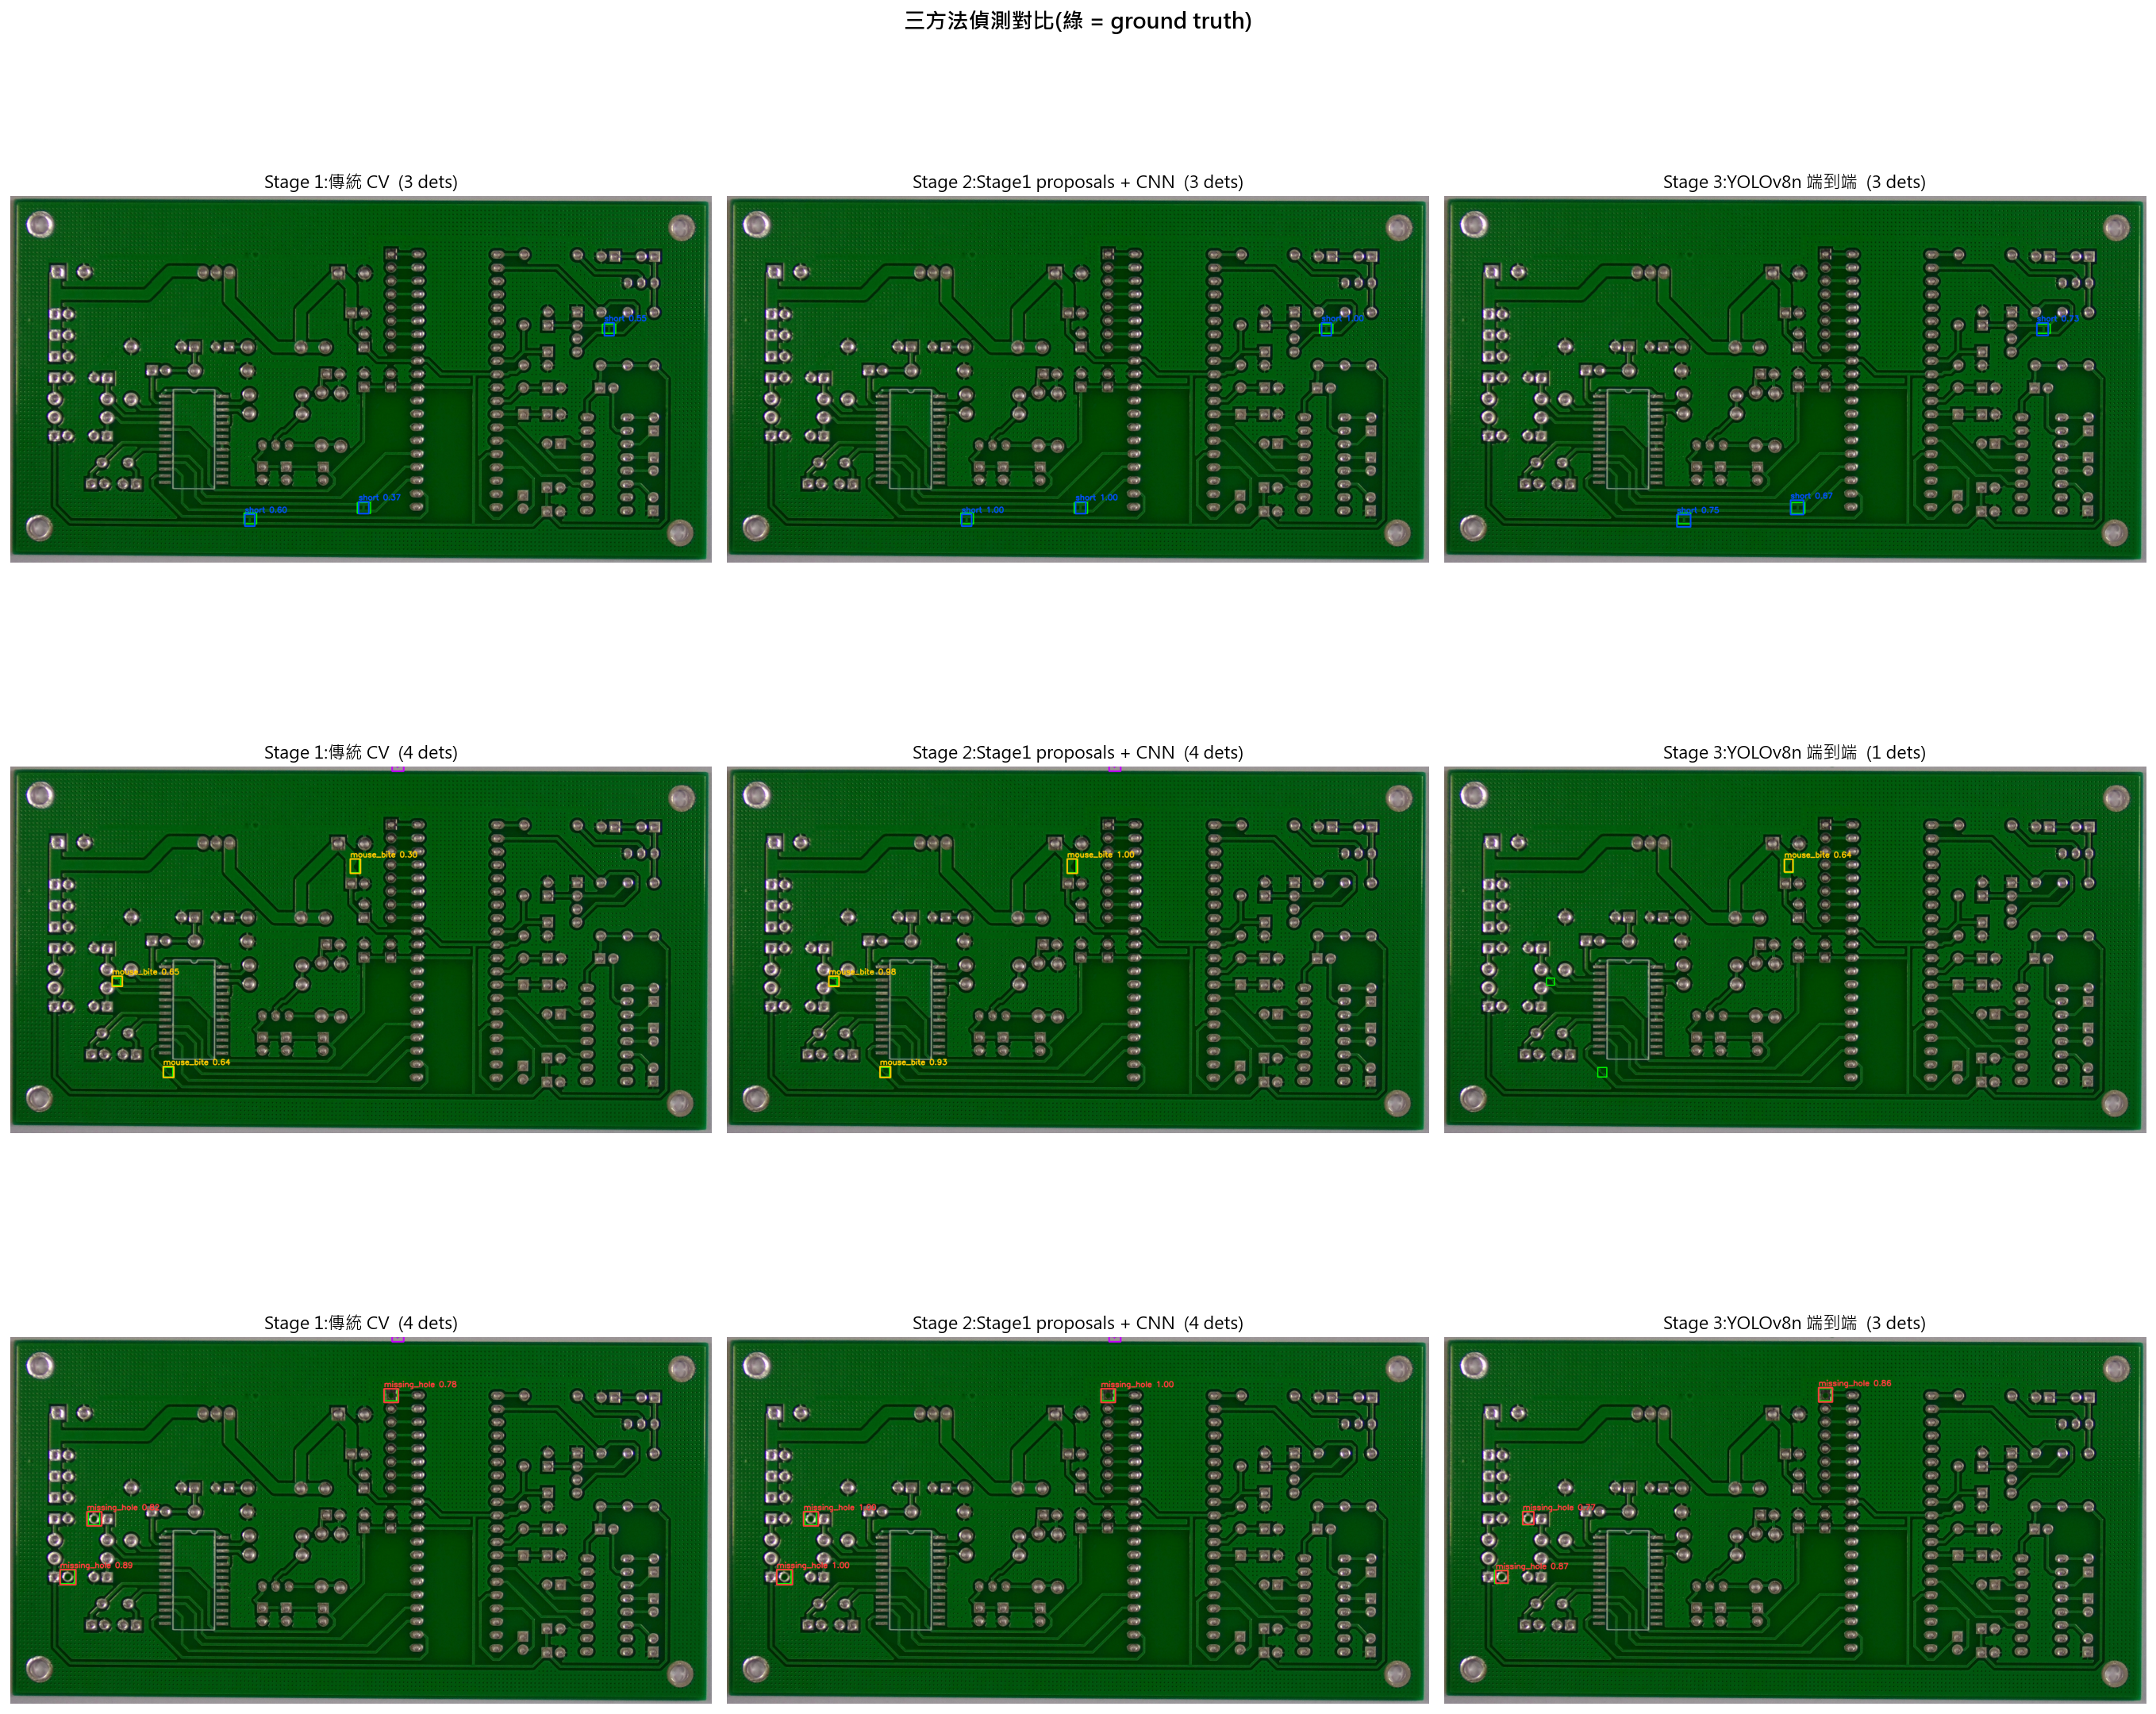

In [6]:
display(Image(filename=str(FIG / "04_methods_comparison_side_by_side.png")))

## 3. 方法取捨分析

| 面向 | Stage 1 傳統 CV | Stage 2 兩階段 DL | Stage 3 端到端 YOLO |
|---|---|---|---|
| **何時選用** | 有 golden template、瑕疵類型固定、推論硬體弱、需高可解釋性 | 有可靠 proposal 來源、分類比定位重要、想重用既有偵測器 | 資料充足、需高 recall、可容忍 black-box |
| **可解釋性** | 高(每步可視覺化) | 中(CNN 為黑箱,但 proposal 可解釋) | 低(端到端黑箱) |
| **訓練成本** | 零(無需標註訓練) | 低(只訓練分類 head,~分鐘) | 中(端到端訓練,~9 分鐘) |
| **部署成本** | CPU 即可,但慢 | 需 GPU,中等 | 需 GPU,但最快(6.3 MB) |
| **可維護性** | 參數需手調,新瑕疵類型難擴充 | 換分類器即可 | 重訓即可,但需重標 |

**核心取捨**:可解釋性與零訓練成本(Stage 1)↔ 精度與速度(Stage 3)。
Stage 2 是兩者之間、重用既有 proposal 的折衷。

## 4. 瓶頸轉移軌跡

整個專案是一條「瓶頸不斷被定位並突破」的軌跡,最能以 **`short`(短路)** 的
per-class AP 佐證:

In [7]:
s = data["per_class_ap50"]
print(f"short AP@0.5:  Stage1 {s['stage1']['short']*100:.1f}%  ->  "
      f"Stage2 {s['stage2']['short']*100:.1f}%  ->  Stage3 {s['stage3']['short']*100:.1f}%")
print()
print("解讀:")
print("  S1: 差影對細銅橋訊號最弱,proposal 階段就漏抓一半 -> 分類能力撞牆")
print("  S2: CNN 在 GT crops 分 short 達 100%,但只拿得到 S1 的 proposals -> 受 recall 綁住")
print("  S3: 端到端直接學定位,不依賴外部 proposal -> 突破瓶頸")

short AP@0.5:  Stage1 19.7%  ->  Stage2 36.2%  ->  Stage3 97.5%

解讀:
  S1: 差影對細銅橋訊號最弱,proposal 階段就漏抓一半 -> 分類能力撞牆
  S2: CNN 在 GT crops 分 short 達 100%,但只拿得到 S1 的 proposals -> 受 recall 綁住
  S3: 端到端直接學定位,不依賴外部 proposal -> 突破瓶頸


## 5. 誠實的限制

1. **mAP@0.5:0.95 = 46.7%(Stage 3)**:框找得到(mAP@0.5 高),但嚴格 IoU 下的
   定位精度仍有空間,與 imgsz=640 對多 MP 影像 downsample 有關(可試 1280)。
2. **混淆矩陣 background 列 FN 偏多**:受 confidence threshold 影響;調低門檻可
   提高 recall 但犧牲 precision。
3. **跨資料集泛化未驗證**:三方法都只在 HRIPCB 訓練 / 測試,未測其他 PCB 影像。
4. **推論時間為單張 inference**:Stage 1 為 CPU pipeline 純運算、Stage 2/3 為 GPU
   forward;皆不含載圖與前後處理(批次推論可再攤提)。
5. **P/R 計算方式**:Stage 1/2 為 conf=0 全 detections 的 macro 平均,Stage 3 為
   conf≥0.25;三者語境略有差異,mAP 才是主要可比指標。

完整數字見 [`results/comparison_table.md`](../results/comparison_table.md)。